# Project 04: Exploratory Data Analysis & Statistical Insights

**Project:** Retail Business Intelligence  
**Prepared by:** Riya Gupta  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy

> **Data note:** This notebook uses 1,200 generated synthetic retail transactions for demonstration because the supplied source file is a data dictionary, not actual transaction records. Results are illustrative and must not be presented as real company performance.

## 1. Objective
Explore transaction patterns, calculate descriptive statistics, visualise distributions and relationships, test three business hypotheses, and summarise five decision-relevant findings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
DATA_FILE = "retail_sample_transactions_SYNTHETIC.csv"
df = pd.read_csv(DATA_FILE)
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 1200 rows × 12 columns


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,gross_revenue,net_revenue,recognized_revenue
0,ORD-00001,2025-03-02,Professional,Gurugram,Course Access,3,4129.61,15,Paid,12388.83,10530.51,10530.51
1,ORD-00002,2026-06-09,Fresher,Noida,Course Access,2,4193.02,0,Paid,8386.04,8386.04,8386.04
2,ORD-00003,2026-03-20,Student,Delhi,Mentor Session,1,1078.22,10,Paid,1078.22,970.40,970.40
3,ORD-00004,2025-10-25,Fresher,Gurugram,Course Access,1,4528.99,0,Paid,4528.99,4528.99,4528.99
4,ORD-00005,2025-10-21,Student,Lucknow,Mentor Session,2,2589.30,10,Paid,5178.60,4660.74,4660.74


## 2. Data understanding and quality checks

In [2]:
display(df.info())
quality_report = pd.DataFrame({
    "Check": ["Missing cells", "Duplicate order IDs", "Invalid dates", "Non-positive quantity", "Negative unit price", "Discount outside 0–100%"],
    "Count": [int(df.isna().sum().sum()), int(df.order_id.duplicated().sum()), int(df.order_date.isna().sum()), int((df.quantity <= 0).sum()), int((df.unit_price < 0).sum()), int((~df.discount_pct.between(0, 100)).sum())]
})
display(quality_report)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            1200 non-null   object        
 1   order_date          1200 non-null   datetime64[ns]
 2   customer_segment    1200 non-null   object        
 3   city                1200 non-null   object        
 4   category            1200 non-null   object        
 5   quantity            1200 non-null   int64         
 6   unit_price          1200 non-null   float64       
 7   discount_pct        1200 non-null   int64         
 8   payment_status      1200 non-null   object        
 9   gross_revenue       1200 non-null   float64       
 10  net_revenue         1200 non-null   float64       
 11  recognized_revenue  1200 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(5)
memory usage: 112.6+ KB


None

,Check,Count
0,Missing cells,0
1,Duplicate order IDs,0
2,Invalid dates,0
3,Non-positive quantity,0
4,Negative unit price,0
5,Discount outside 0–100%,0


## 3. Descriptive statistics
The summary below reports count, mean, standard deviation, minimum, quartiles and maximum for numerical variables. Median is the 50th percentile.

In [3]:
numeric_cols = ["quantity", "unit_price", "discount_pct", "gross_revenue", "net_revenue", "recognized_revenue"]
descriptive_stats = df[numeric_cols].describe().T
descriptive_stats["median"] = df[numeric_cols].median()
display(descriptive_stats[["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max"]].round(2))

,count,mean,median,std,min,25%,50%,75%,max
quantity,1200.0,2.50,2.00,1.10,1.00,2.00,2.00,3.00,4.00
unit_price,1200.0,2723.46,2375.25,1351.36,710.90,1674.55,2375.25,3464.71,5998.87
discount_pct,1200.0,9.60,10.00,7.29,0.00,5.00,10.00,15.00,25.00
gross_revenue,1200.0,6811.30,5485.67,4781.32,730.85,3298.72,5485.67,9122.95,23943.72
net_revenue,1200.0,6153.50,4932.73,4318.54,656.71,2942.71,4932.73,8303.50,23778.20
recognized_revenue,1200.0,4822.77,3761.36,4628.60,0.00,1265.63,3761.36,6972.24,23630.56


## 4. Distribution analysis: histograms

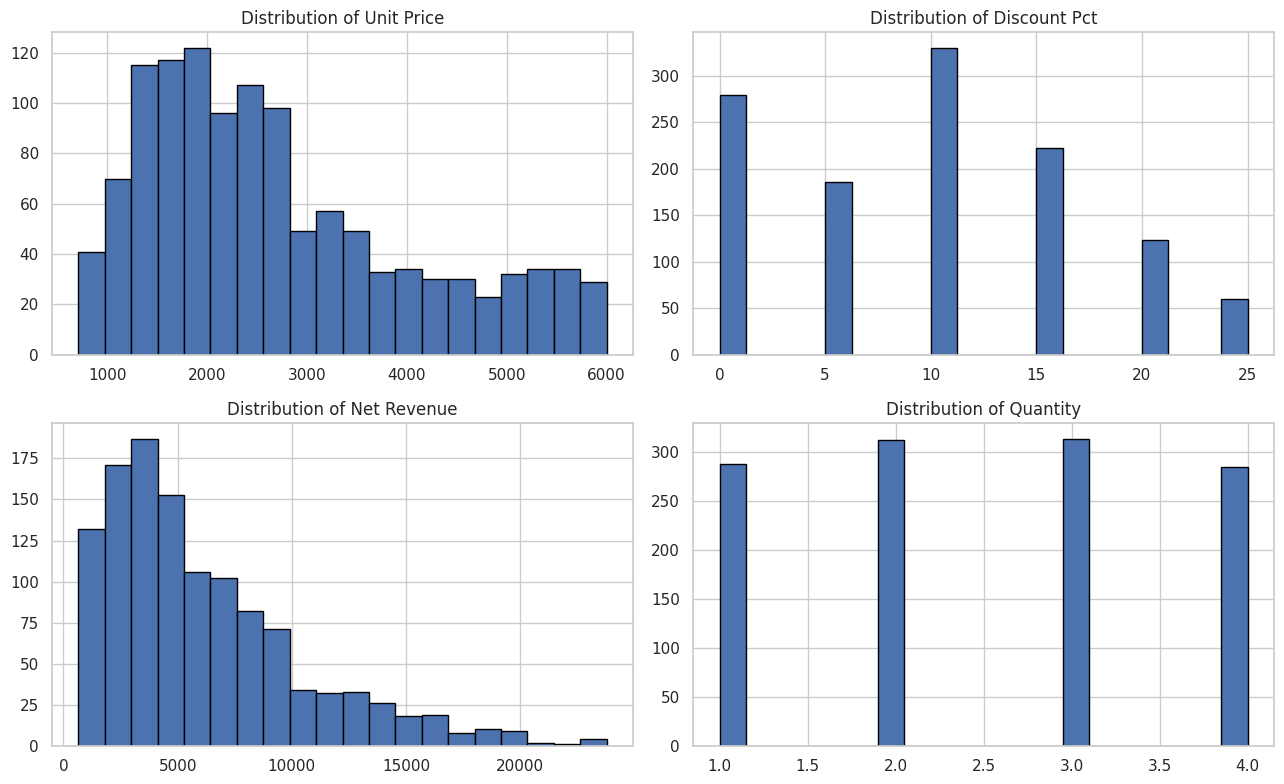

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["unit_price", "discount_pct", "net_revenue", "quantity"]):
    ax.hist(df[col].dropna(), bins=20, edgecolor="black")
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
plt.tight_layout()
plt.show()

## 5. Outlier detection: box plots
Box plots use the 1.5 × IQR rule to flag potential outliers. These points require investigation; they are not automatically errors.

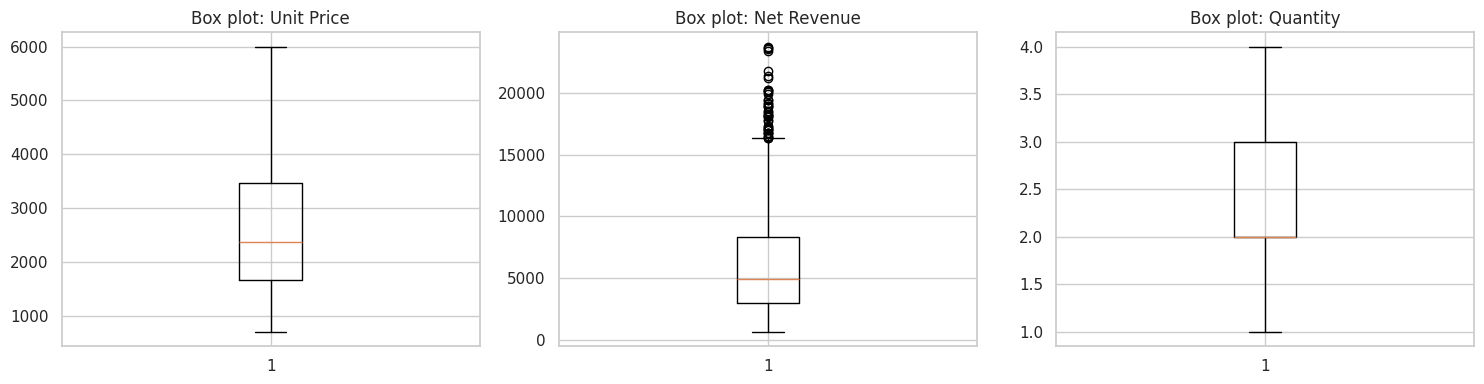

unit_price      0
net_revenue    41
quantity        0
Name: Potential outlier count, dtype: int64

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["unit_price", "net_revenue", "quantity"]):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(f"Box plot: {col.replace('_', ' ').title()}")
plt.tight_layout()
plt.show()

outlier_summary = {}
for col in ["unit_price", "net_revenue", "quantity"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary[col] = int(((df[col] < lower) | (df[col] > upper)).sum())
display(pd.Series(outlier_summary, name="Potential outlier count"))

## 6. Correlation analysis
Pearson correlation measures linear association between numerical variables. Correlation does not establish causation.

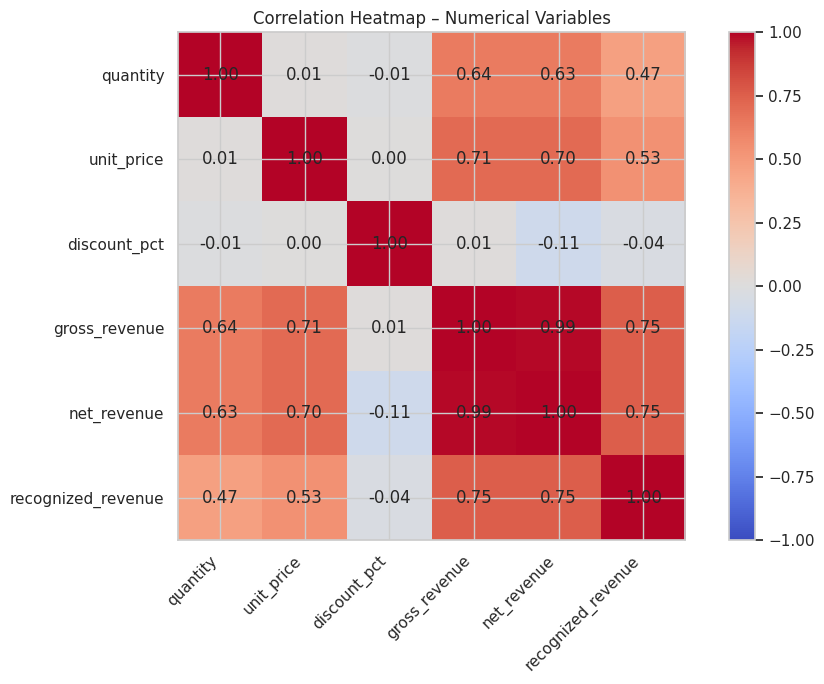

,quantity,unit_price,discount_pct,gross_revenue,net_revenue,recognized_revenue
quantity,1.000,0.008,-0.013,0.637,0.634,0.468
unit_price,0.008,1.000,0.003,0.710,0.704,0.534
discount_pct,-0.013,0.003,1.000,0.011,-0.106,-0.037
gross_revenue,0.637,0.710,0.011,1.000,0.990,0.754
net_revenue,0.634,0.704,-0.106,0.990,1.000,0.750
recognized_revenue,0.468,0.534,-0.037,0.754,0.750,1.000


In [6]:
corr = df[numeric_cols].corr(method="pearson")
plt.figure(figsize=(10, 7))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation Heatmap – Numerical Variables")
plt.tight_layout()
plt.show()
display(corr.round(3))

## 7. Business hypothesis testing
Significance level: **α = 0.05**. A p-value below 0.05 indicates evidence against the null hypothesis under the selected test assumptions. Statistical significance is not the same as business importance.

### Hypothesis 1 — Discount level and net revenue
**H₀:** Discount percentage and net revenue have no monotonic association.  
**H₁:** Discount percentage and net revenue have a monotonic association.  
Test: Spearman rank correlation. This is an association test, not a causal estimate of discount impact.

In [7]:
h1 = df[["discount_pct", "net_revenue"]].dropna()
rho, p1 = stats.spearmanr(h1["discount_pct"], h1["net_revenue"])
print(f"Spearman rho = {rho:.3f}; p-value = {p1:.4g}")
print("Decision:", "Reject H0" if p1 < 0.05 else "Fail to reject H0")

Spearman rho = -0.127; p-value = 9.599e-06
Decision: Reject H0


### Hypothesis 2 — Revenue differs across customer segments
**H₀:** Net revenue distributions are the same across customer segments.  
**H₁:** At least one customer segment has a different net revenue distribution.  
Test: Kruskal–Wallis H-test, a non-parametric comparison across three or more independent groups.

In [8]:
segment_groups = [g["net_revenue"].dropna().values for _, g in df.groupby("customer_segment")]
h2_stat, p2 = stats.kruskal(*segment_groups)
print(f"Kruskal-Wallis H = {h2_stat:.3f}; p-value = {p2:.4g}")
print("Decision:", "Reject H0" if p2 < 0.05 else "Fail to reject H0")
display(df.groupby("customer_segment")["net_revenue"].agg(["count", "mean", "median", "std"]).round(2))

Kruskal-Wallis H = 0.057; p-value = 0.9719
Decision: Fail to reject H0


,count,mean,median,std
customer_segment,,,,
Fresher,404,6200.79,4620.59,4428.20
Professional,292,6246.93,4966.93,4581.12
Student,504,6061.47,5074.37,4072.85


### Hypothesis 3 — Payment status is associated with product category
**H₀:** Payment status and product category are independent.  
**H₁:** Payment status and product category are associated.  
Test: Chi-square test of independence. Expected cell counts should be checked before interpreting the result.

In [9]:
contingency = pd.crosstab(df["category"], df["payment_status"])
chi2, p3, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square = {chi2:.3f}; degrees of freedom = {dof}; p-value = {p3:.4g}")
print("Minimum expected cell count:", round(expected.min(), 2))
print("Decision:", "Reject H0" if p3 < 0.05 else "Fail to reject H0")
display(contingency)

Chi-square = 0.901; degrees of freedom = 6; p-value = 0.9891
Minimum expected cell count: 16.08
Decision: Fail to reject H0


payment_status,Failed,Paid,Pending,Refunded
category,,,,
Course Access,39,454,49,31
Learning Kit,24,261,33,21
Mentor Session,21,225,27,15


## 8. Supporting business visuals

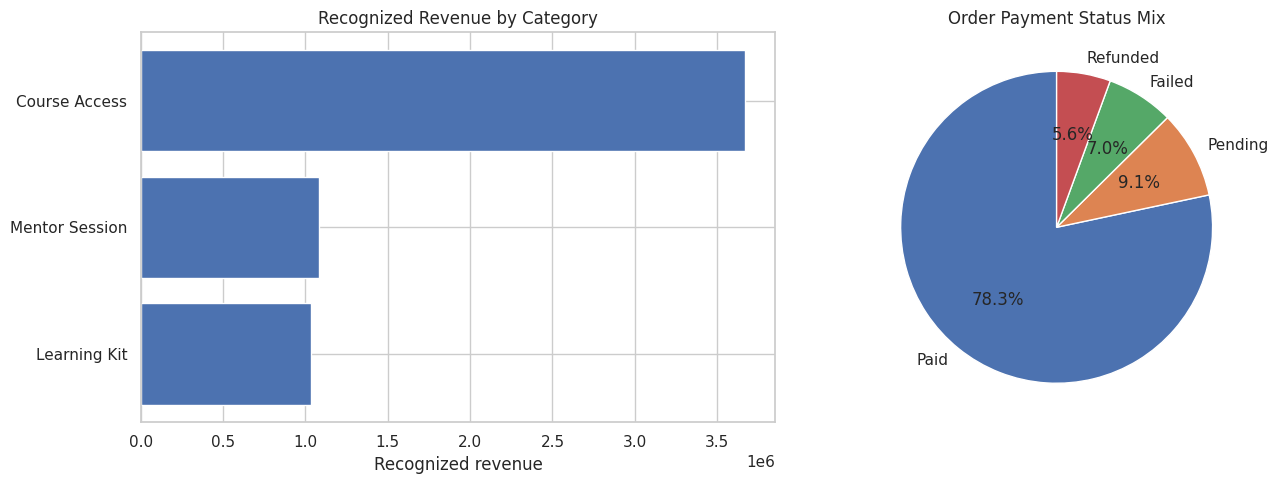

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
category_revenue = df.groupby("category")["recognized_revenue"].sum().sort_values(ascending=False)
axes[0].barh(category_revenue.index, category_revenue.values)
axes[0].invert_yaxis()
axes[0].set_title("Recognized Revenue by Category")
axes[0].set_xlabel("Recognized revenue")
status_share = df["payment_status"].value_counts()
axes[1].pie(status_share.values, labels=status_share.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Order Payment Status Mix")
plt.tight_layout()
plt.show()

## 9. Top five critical findings
The statements below are generated from the loaded dataset. Because the data is synthetic, they are demonstration findings only.

In [11]:
total_orders = len(df)
paid = df[df.payment_status.eq("Paid")]
paid_share = len(paid) / total_orders if total_orders else np.nan
category_share = (category_revenue.iloc[0] / category_revenue.sum() * 100) if category_revenue.sum() else 0
top_category = category_revenue.index[0] if len(category_revenue) else "N/A"
top_segment = df.groupby("customer_segment")["recognized_revenue"].sum().idxmax()
non_paid = total_orders - len(paid)
findings = [
    f"The dataset contains {total_orders:,} orders; {len(paid):,} are marked Paid ({paid_share:.1%}).",
    f"{non_paid:,} orders are not marked Paid and should be reconciled by payment status before revenue reporting.",
    f"{top_category} is the leading category by recognized revenue, contributing {category_share:.1f}% of recognized revenue.",
    f"{top_segment} is the highest recognized-revenue customer segment in this sample.",
    f"The discount–net revenue Spearman test has p={p1:.4g}; interpret the association cautiously because order value, category and customer mix may confound it."
]
for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")

1. The dataset contains 1,200 orders; 940 are marked Paid (78.3%).
2. 260 orders are not marked Paid and should be reconciled by payment status before revenue reporting.
3. Course Access is the leading category by recognized revenue, contributing 63.4% of recognized revenue.
4. Student is the highest recognized-revenue customer segment in this sample.
5. The discount–net revenue Spearman test has p=9.599e-06; interpret the association cautiously because order value, category and customer mix may confound it.


## 10. Conclusion and business recommendations
- Monitor Paid, Pending, Failed and Refunded orders separately; reconcile gateway records before follow-up.
- Review category and segment performance using recognised revenue and order counts together.
- Treat discounts as an experiment: use matched cohorts or an A/B test and add product cost/margin data before claiming profitability impact.
- Investigate potential outliers against source records rather than deleting them automatically.
- Add customer identifiers and repeat-purchase history before attempting retention, churn or lifetime-value analysis.

**Limitations:** This dataset is synthetic. It has no customer-level history, cost of goods, marketing spend or verified margin fields. Therefore, actual retention, profit, ROI and causal discount effects cannot be established. Replace the sample CSV with authorised transaction data before making real business claims.

## 11. Reproducibility
Keep `Project04_Exploratory_Data_Analysis.ipynb` and `retail_sample_transactions_SYNTHETIC.csv` in the same folder. Run all cells from top to bottom. The notebook requires `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, and `ipython`.